In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import scrublet as scr
import matplotlib.pyplot as plt
import matplotlib
from matplotlib import rcParams
from matplotlib import rc
from matplotlib import colors
import seaborn as sb
from collections import Counter
import glob

sc.settings.set_figure_params(dpi = 160, color_map = 'RdPu', dpi_save = 300, format = 'pdf')
plt.rcParams["figure.figsize"] = [6,6]
plt.rcParams["pdf.fonttype"] = 42 # add pdf text as one piece instead of letter by letter

In [2]:
sb.set_palette('colorblind')

In [3]:
# set working directory
%cd /nfs/team205/cs42/HSC/HSC_new_to_transfer

/nfs/team205/cs42/HSC/HSC_new_to_transfer


In [4]:
# figure directory
fig_path = 'figure/'
sc.settings.figdir = fig_path

# Load data

In [5]:
adata = sc.read('write/hom_screen_entire_data_normalised_log.h5ad')

In [6]:
adata

AnnData object with n_obs × n_vars = 10453 × 36601
    obs: 'n_counts_GEX', 'n_genes', 'n_counts_antibody_capture', 'mito', 'file', 'sanger_sample_ID', 'screen_no', 'HSC_days', 'FACS_sort', '10x_kit', 'doublet_scores', 'predicted_doublets', 'batch', 'top1_barcode', 'top1_count', 'top2_barcode', 'top2_count', 'n_called_barcodes'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'log1p'

In [7]:
#adata.raw = adata.copy()

# Build UMAP

In [8]:
np.median(adata.obs['n_genes'])

np.float64(4601.0)

In [9]:
sc.pp.highly_variable_genes(adata, batch_key="file")

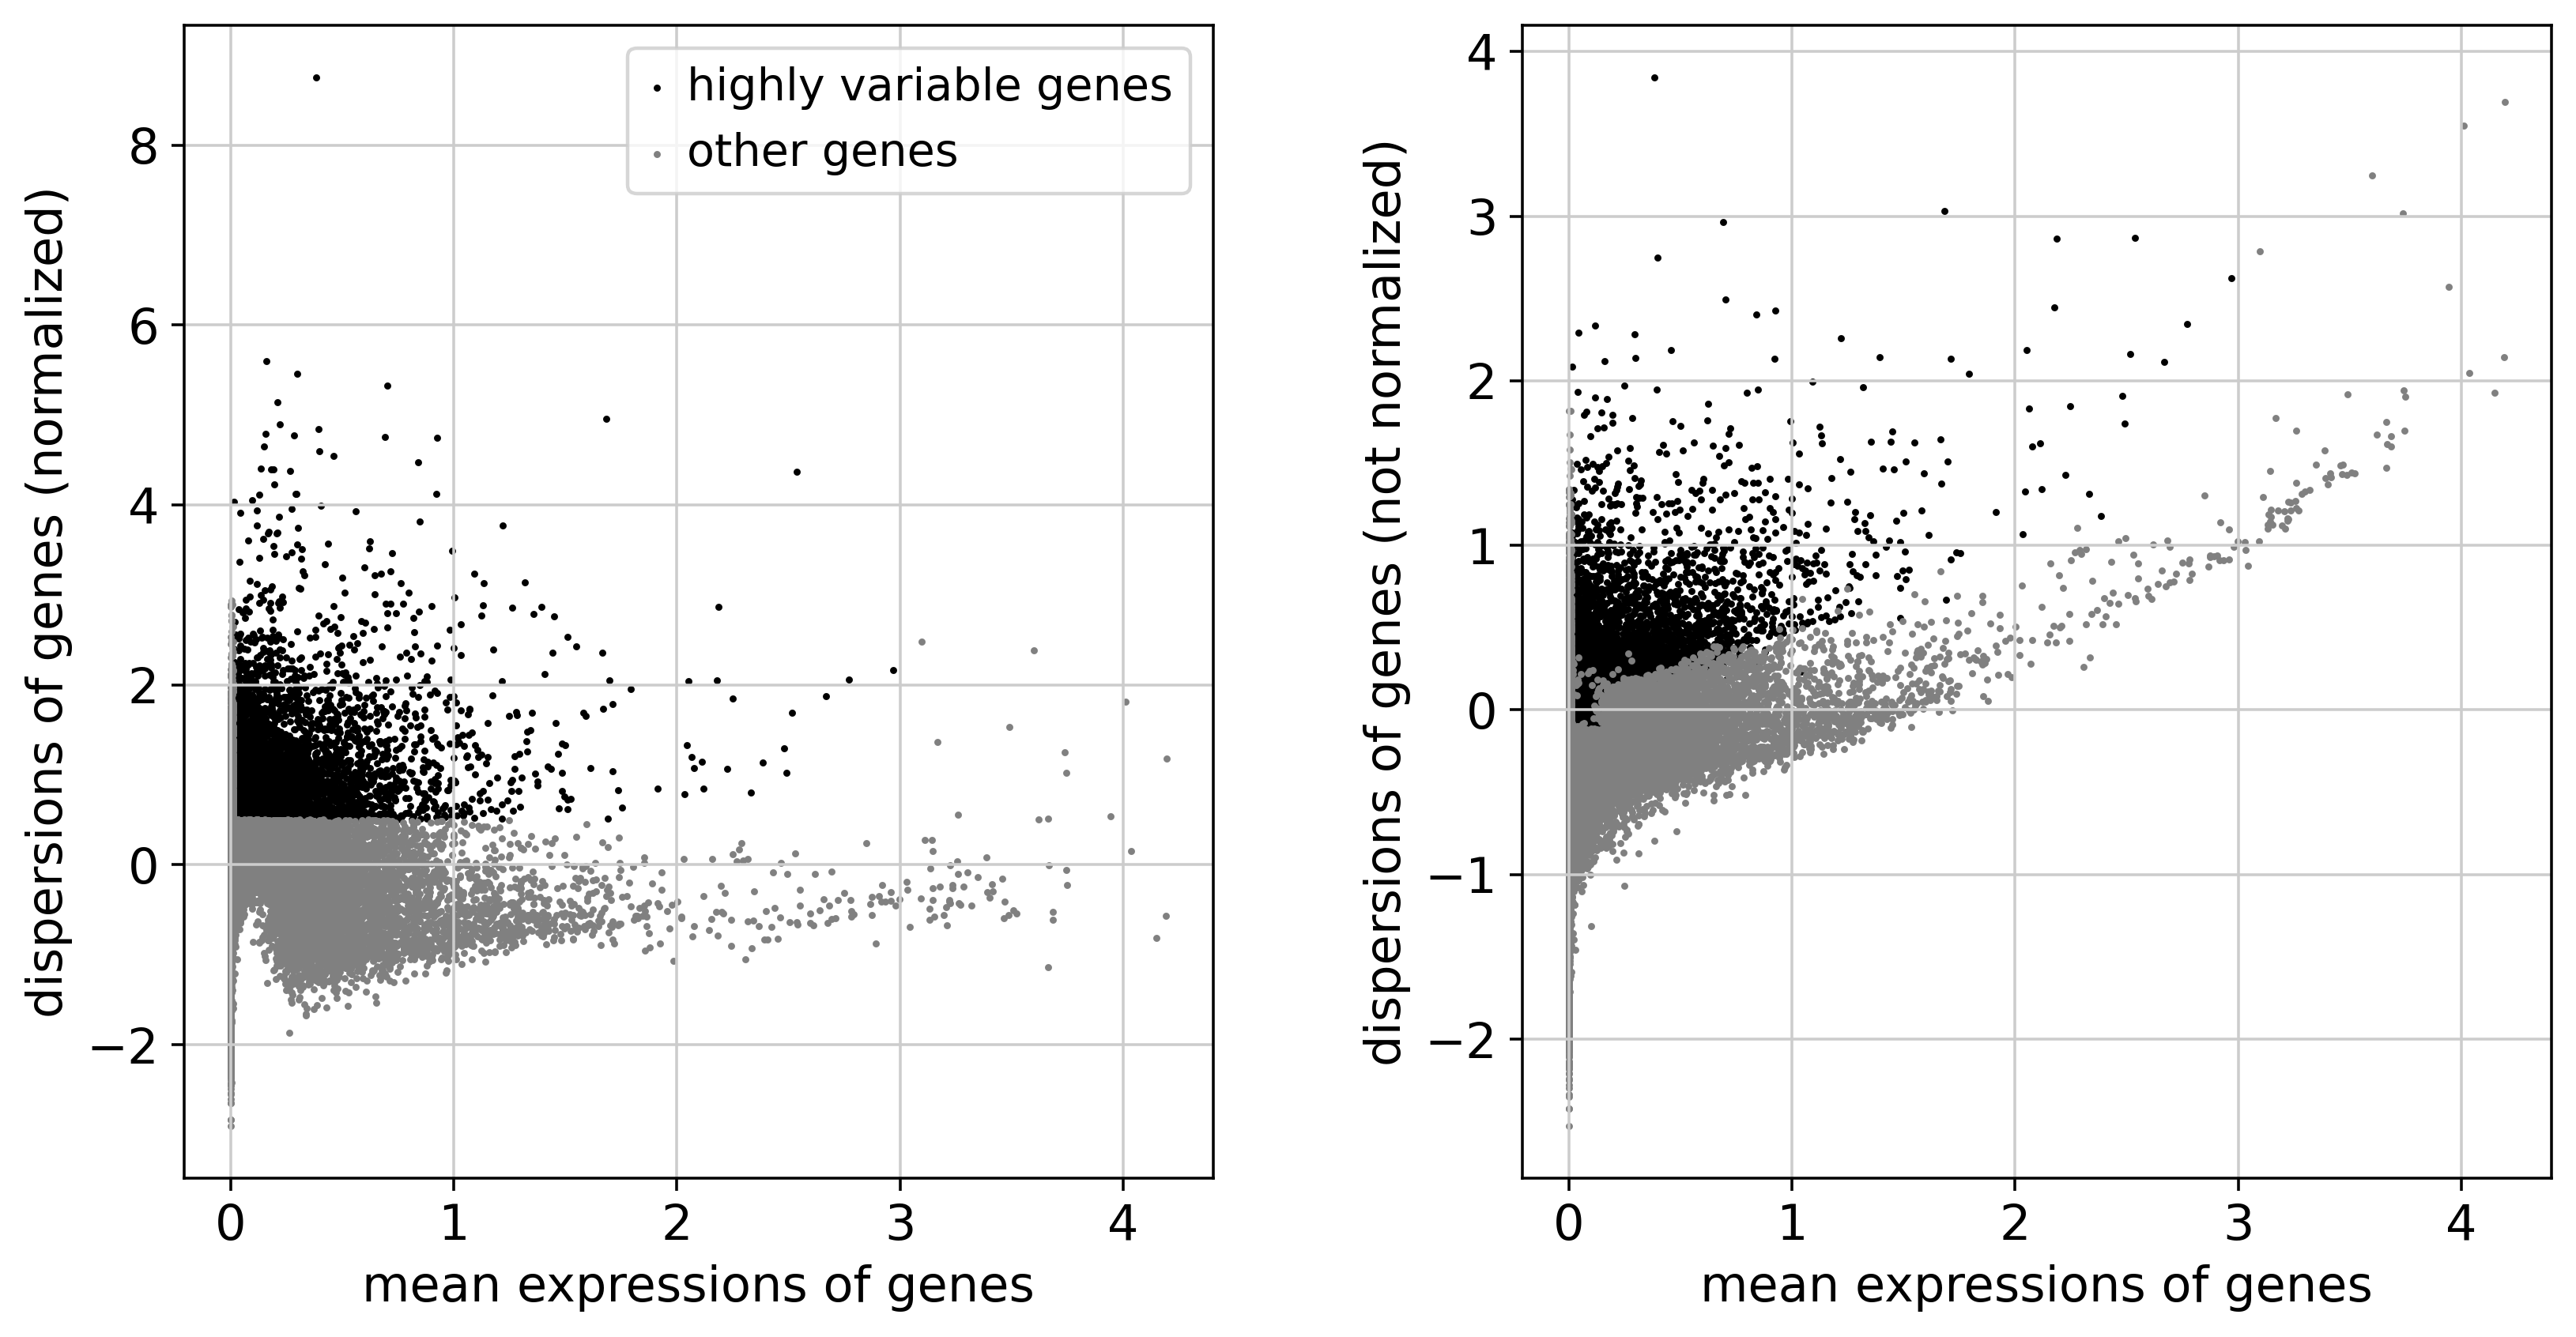

In [10]:
sc.pl.highly_variable_genes(adata)

In [11]:
sc.tl.pca(adata, random_state=1712)

In [12]:
sc.pp.neighbors(adata, random_state=1712)

In [13]:
sc.tl.umap(adata, random_state=1712)

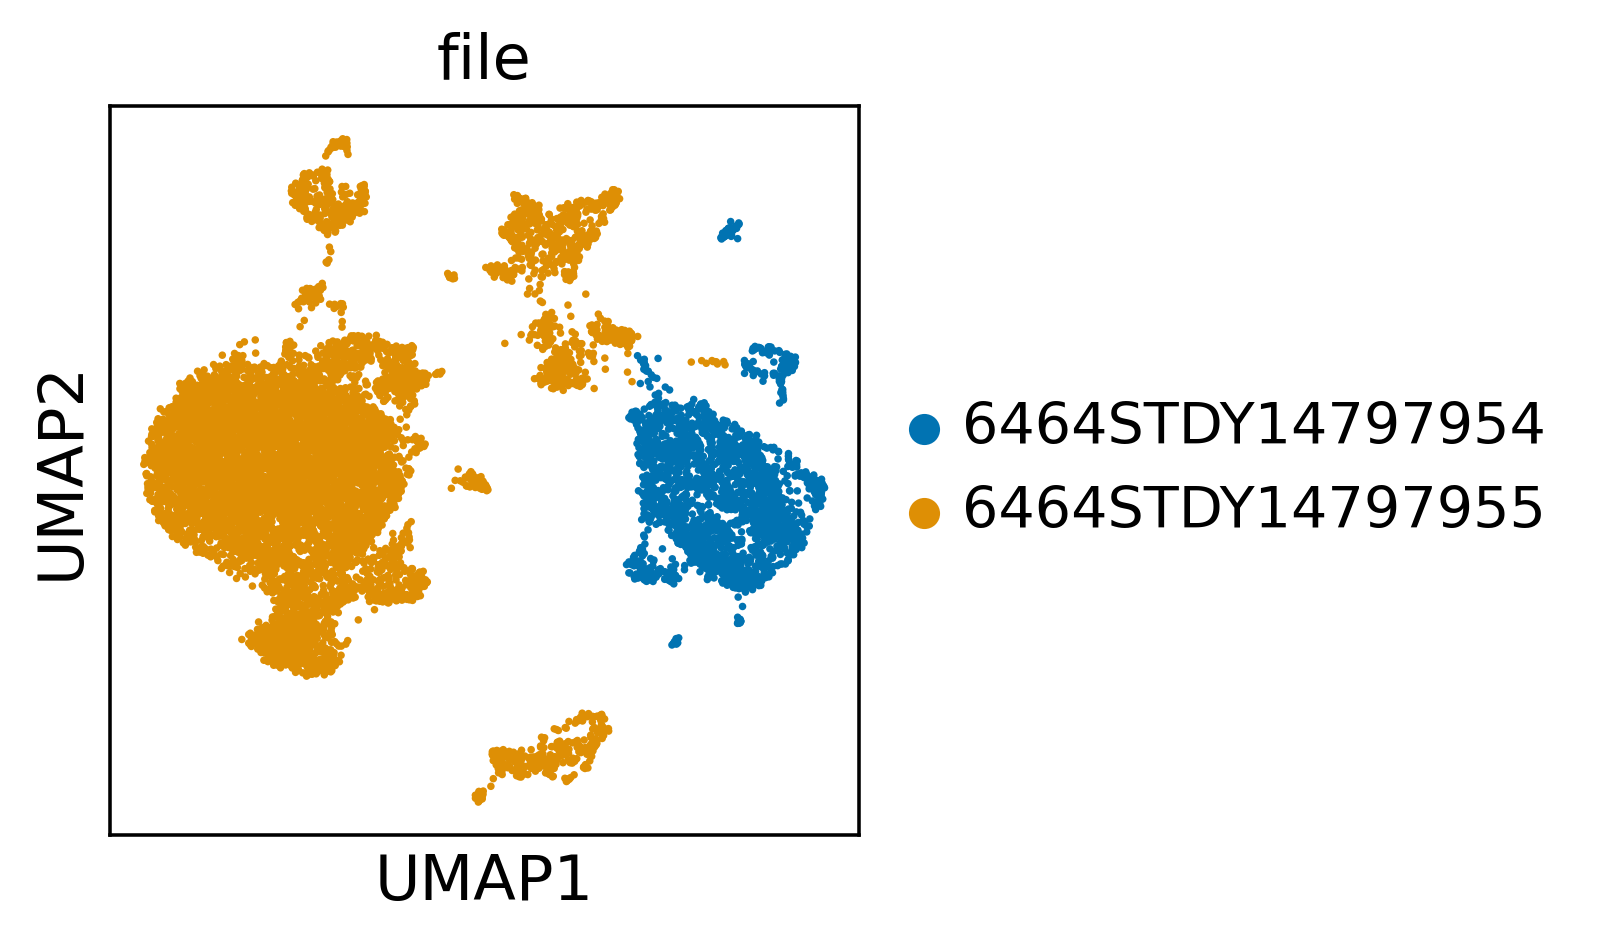

In [14]:
plt.rcParams["figure.figsize"] = [3,3]
sc.pl.umap( adata,
    color="file"
)

# Celltypist

In [15]:
import celltypist
from celltypist import models

In [16]:
import importlib.metadata as md
print(md.version("celltypist"))

1.6.3


In [17]:
# Enabling `force_update = True` will overwrite existing (old) models.
models.download_models(force_update = True)

📜 Retrieving model list from server https://celltypist.cog.sanger.ac.uk/models/models.json
📚 Total models in list: 61
📂 Storing models in /nfs/users/nfs_c/cs42/.celltypist/data/models
💾 Downloading model [1/61]: Immune_All_Low.pkl
💾 Downloading model [2/61]: Immune_All_High.pkl
💾 Downloading model [3/61]: Adult_COVID19_PBMC.pkl
💾 Downloading model [4/61]: Adult_CynomolgusMacaque_Hippocampus.pkl
💾 Downloading model [5/61]: Adult_Human_MTG.pkl
💾 Downloading model [6/61]: Adult_Human_PancreaticIslet.pkl
💾 Downloading model [7/61]: Adult_Human_PrefrontalCortex.pkl
💾 Downloading model [8/61]: Adult_Human_Skin.pkl
💾 Downloading model [9/61]: Adult_Human_Vascular.pkl
💾 Downloading model [10/61]: Adult_Mouse_Gut.pkl
💾 Downloading model [11/61]: Adult_Mouse_OlfactoryBulb.pkl
💾 Downloading model [12/61]: Adult_Pig_Hippocampus.pkl
💾 Downloading model [13/61]: Adult_RhesusMacaque_Hippocampus.pkl
💾 Downloading model [14/61]: Adult_cHSPCs_Illumina.pkl
💾 Downloading model [15/61]: Adult_cHSPCs_Ultima

In [18]:
predictions = celltypist.annotate(adata, model = 'Pan_Fetal_Human.pkl', majority_voting = True)

🔬 Input data has 10453 cells and 36601 genes
🔗 Matching reference genes in the model
🧬 7121 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!
👀 Detected a neighborhood graph in the input object, will run over-clustering on the basis of it
⛓️ Over-clustering input data with resolution set to 10
🗳️ Majority voting the predictions
✅ Majority voting done!


In [19]:
# Get an `AnnData` with predicted labels embedded into the cell metadata columns.
adata = predictions.to_adata()

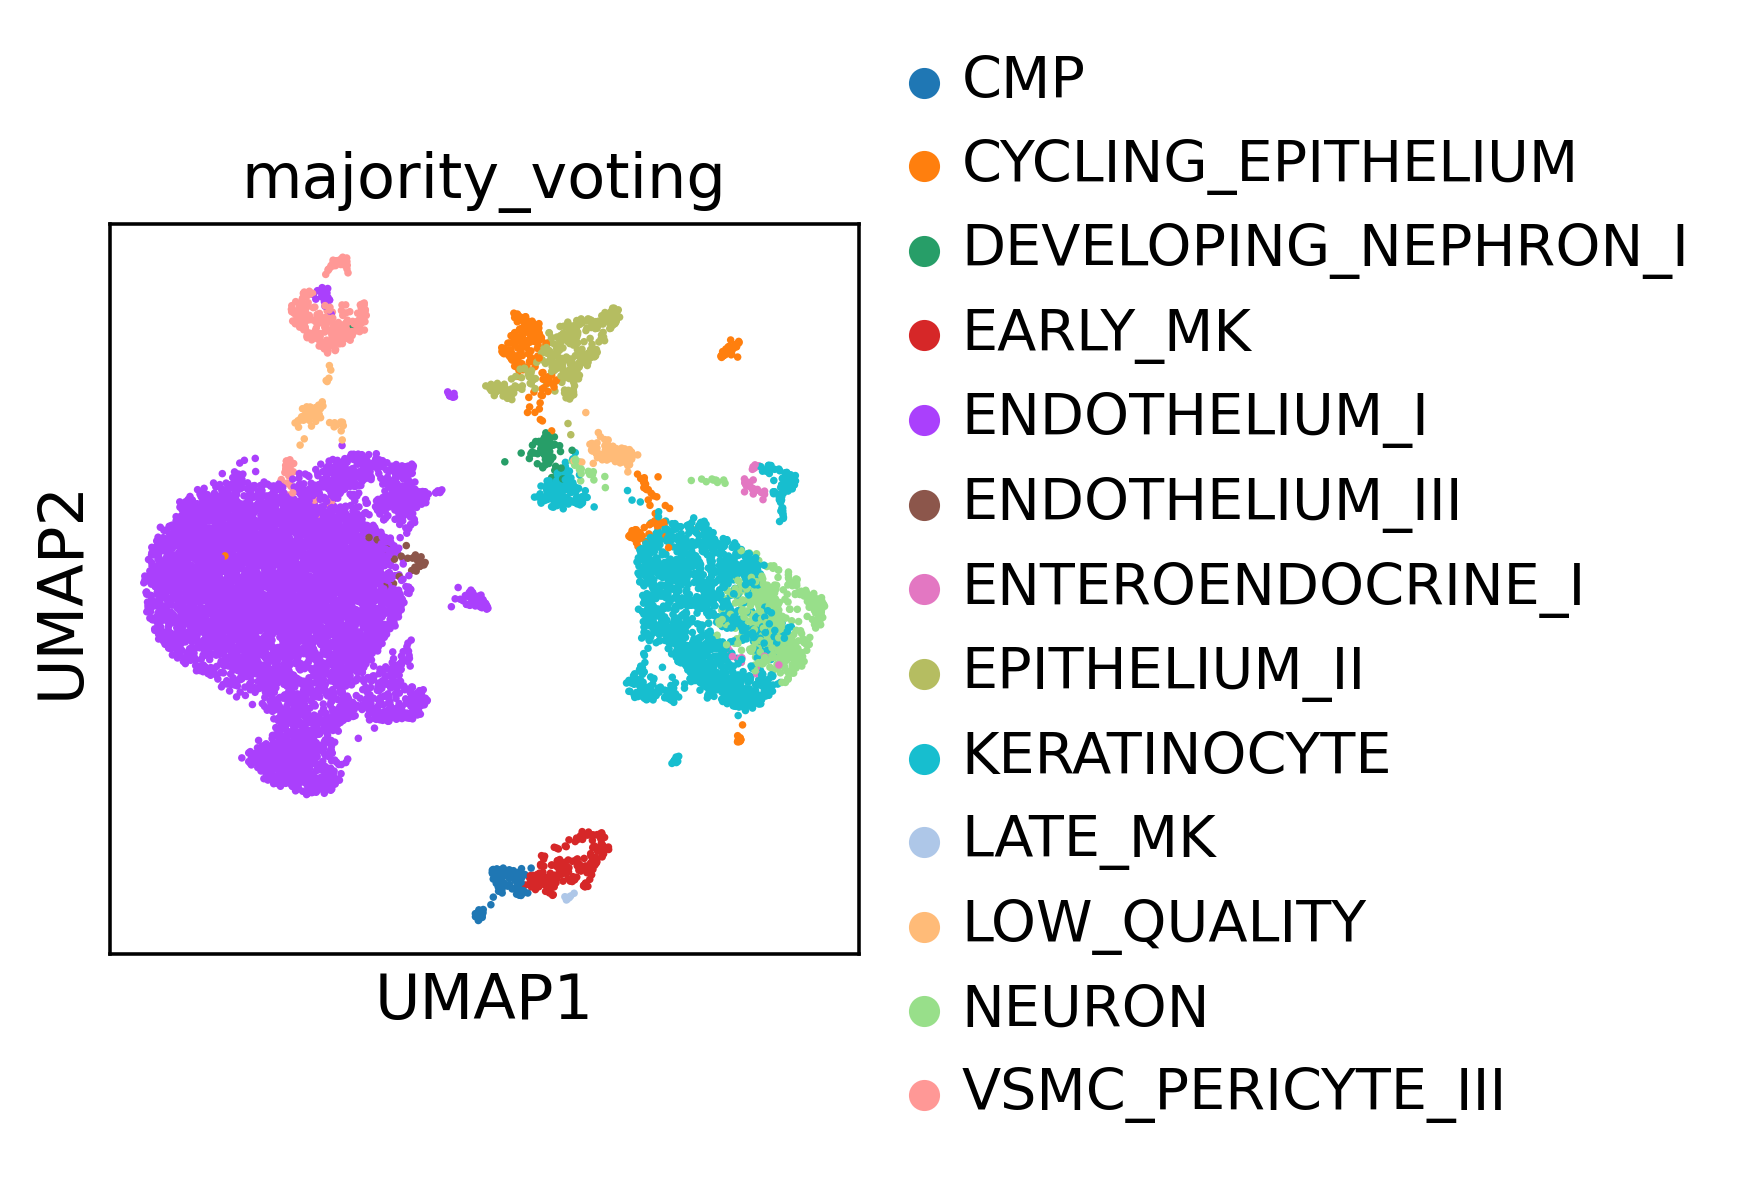

In [20]:
sc.pl.umap(adata, color=['majority_voting'])

In [21]:
adata.write_h5ad('write/hom_screen_celltypist.h5ad')

In [5]:
adata = sc.read('write/hom_screen_celltypist.h5ad')